In [6]:
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Path to your organized images folder
base_path = "D:/Datasets/ChestXray/all_images"

# Define image transformations (resize, normalize, etc.)
transform = transforms.Compose([
    transforms.Resize((224, 224)),          # Resize images to 224x224
    transforms.ToTensor(),                   # Convert PIL Image to tensor
    transforms.Normalize([0.485, 0.456, 0.406],  # Normalize using ImageNet mean/std
                         [0.229, 0.224, 0.225])
])

# Load dataset using ImageFolder (labels = folder names)
dataset = datasets.ImageFolder(root=base_path, transform=transform)

# Print classes and dataset size
print("Classes found:", dataset.classes)
print("Total images:", len(dataset))

# Create DataLoader for batching
batch_size = 32
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=4)

# Optional: check one batch to verify
images, labels = next(iter(dataloader))
print(f"Batch images shape: {images.shape}")
print(f"Batch labels shape: {labels.shape}")


Classes found: ['images_001', 'images_002', 'images_003', 'images_004', 'images_005', 'images_006', 'images_007', 'images_008', 'images_009', 'images_010', 'images_011', 'images_012']
Total images: 112120
Batch images shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32])


In [7]:
import pandas as pd

# Path to the CSV file
csv_path = "D:/Datasets/ChestXray/Data_Entry_2017.csv"

# Load the CSV into a DataFrame
df = pd.read_csv(csv_path)

# Show first few rows to understand the data
print(df.head())

# Split the 'Finding Labels' column by '|' to create lists of diseases per image
df['Finding Labels'] = df['Finding Labels'].apply(lambda x: x.split('|'))

# Verify the label splitting
print(df[['Image Index', 'Finding Labels']].head())


        Image Index          Finding Labels  Follow-up #  Patient ID  \
0  00000001_000.png            Cardiomegaly            0           1   
1  00000001_001.png  Cardiomegaly|Emphysema            1           1   
2  00000001_002.png   Cardiomegaly|Effusion            2           1   
3  00000002_000.png              No Finding            0           2   
4  00000003_000.png                  Hernia            0           3   

   Patient Age Patient Gender View Position  OriginalImage[Width  Height]  \
0           58              M            PA                 2682     2749   
1           58              M            PA                 2894     2729   
2           58              M            PA                 2500     2048   
3           81              M            PA                 2500     2048   
4           81              F            PA                 2582     2991   

   OriginalImagePixelSpacing[x     y]  Unnamed: 11  
0                        0.143  0.143          NaN 

In [8]:
# Step 3: Extract all unique diseases (classes)
all_labels = set()
for labels in df['Finding Labels']:
    all_labels.update(labels)
all_labels = sorted(list(all_labels))

print("All unique disease classes:")
print(all_labels)


All unique disease classes:
['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'No Finding', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']


In [9]:
from sklearn.preprocessing import MultiLabelBinarizer

# Initialize MultiLabelBinarizer with your disease classes
mlb = MultiLabelBinarizer(classes=all_labels)

# Fit and transform the label lists into multi-hot encoded numpy array
label_matrix = mlb.fit_transform(df['Finding Labels'])

# Check shape and example
print("Label matrix shape:", label_matrix.shape)
print("Sample multi-hot label vector for first image:", label_matrix[0])
print("Corresponding diseases:", [all_labels[i] for i, val in enumerate(label_matrix[0]) if val == 1])


Label matrix shape: (112120, 15)
Sample multi-hot label vector for first image: [0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
Corresponding diseases: ['Cardiomegaly']


In [11]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset

class ChestXrayDataset(Dataset):
    def __init__(self, df, label_matrix, base_img_path, transform=None):
        self.df = df.reset_index(drop=True)
        self.labels = torch.tensor(label_matrix, dtype=torch.float32)
        self.base_img_path = base_img_path
        self.transform = transform
        
        # Build a filename -> full image path mapping for quick lookup
        self.filename_to_path = {}
        for subfolder in os.listdir(base_img_path):
            full_subfolder = os.path.join(base_img_path, subfolder)
            if os.path.isdir(full_subfolder):
                for fname in os.listdir(full_subfolder):
                    self.filename_to_path[fname] = os.path.join(full_subfolder, fname)
    
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Image Index']
        img_path = self.filename_to_path.get(img_name, None)
        if img_path is None:
            raise FileNotFoundError(f"Image {img_name} not found in {self.base_img_path}")
        
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        
        label = self.labels[idx]
        return image, label


In [12]:
from torchvision import transforms

# Define your image transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),            # Resize to 224x224
    transforms.ToTensor(),                     # Convert to tensor
    transforms.Normalize([0.485, 0.456, 0.406],  # Normalize like ImageNet
                         [0.229, 0.224, 0.225])
])

base_image_path = "D:/Datasets/ChestXray/all_images"

# Create dataset instance
dataset = ChestXrayDataset(df, label_matrix, base_image_path, transform=transform)

print(f"Dataset size: {len(dataset)}")
print(f"Sample label vector (multi-hot): {dataset[0][1]}")


Dataset size: 112120
Sample label vector (multi-hot): tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


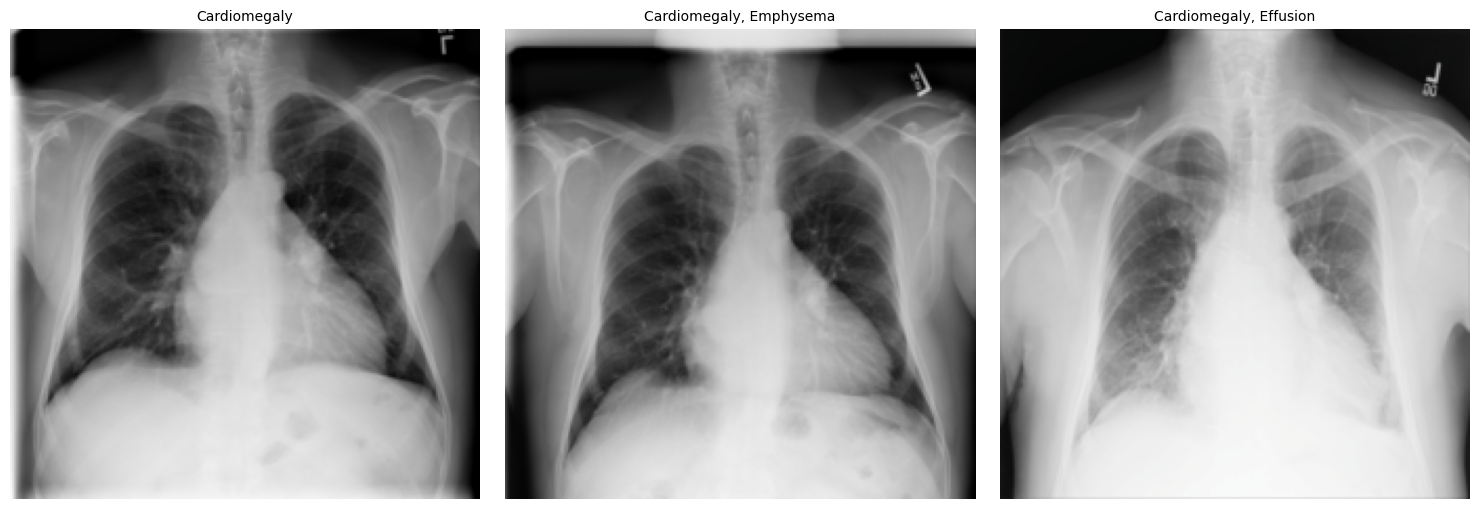

In [13]:
import matplotlib.pyplot as plt
import numpy as np

def imshow(img_tensor, ax):
    img = img_tensor.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean  # unnormalize
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    ax.axis('off')

classes = all_labels  # your disease list

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for i in range(3):
    image, label = dataset[i]
    title = ", ".join([classes[j] for j, val in enumerate(label) if val == 1])
    axs[i].set_title(title, fontsize=10)
    imshow(image, axs[i])
plt.tight_layout()
plt.show()


In [14]:
from torch.utils.data import Dataset
from PIL import Image
import os
import torch

class ChestXrayDataset(Dataset):
    def __init__(self, df, label_matrix, base_img_path, transform=None):
        self.df = df.reset_index(drop=True)
        self.labels = torch.tensor(label_matrix, dtype=torch.float32)
        self.base_img_path = base_img_path
        self.transform = transform

        # Build filename-to-path dict once
        self.filename_to_path = {}
        for subfolder in os.listdir(base_img_path):
            full_subfolder = os.path.join(base_img_path, subfolder)
            if os.path.isdir(full_subfolder):
                for fname in os.listdir(full_subfolder):
                    self.filename_to_path[fname] = os.path.join(full_subfolder, fname)
        print(f"Built filename_to_path dictionary with {len(self.filename_to_path)} entries")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Image Index']
        img_path = self.filename_to_path.get(img_name, None)
        if img_path is None:
            raise FileNotFoundError(f"Image {img_name} not found")
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        label = self.labels[idx]
        return image, label


In [15]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

base_image_path = "D:/Datasets/ChestXray/all_images"

dataset = ChestXrayDataset(df, label_matrix, base_image_path, transform=transform)


Built filename_to_path dictionary with 112120 entries


In [16]:
from torch.utils.data import DataLoader

batch_size = 32

dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0)

# Test one batch
images, labels = next(iter(dataloader))
print(f"Batch images shape: {images.shape}")
print(f"Batch labels shape: {labels.shape}")

import time

start = time.time()
images, labels = next(iter(dataloader))
end = time.time()

print(f"Batch load time with num_workers={dataloader.num_workers}: {end - start:.3f} seconds")
print(f"Batch images shape: {images.shape}")
print(f"Batch labels shape: {labels.shape}")


Batch images shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32, 15])
Batch load time with num_workers=0: 2.025 seconds
Batch images shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32, 15])


In [17]:
import torch
import torch.nn as nn
import torchvision.models as models

# Number of disease classes
num_classes = len(all_labels)  # e.g., 15

# Load pretrained ResNet18
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Replace the final fully connected layer to match our num_classes
model.fc = nn.Linear(model.fc.in_features, num_classes)

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(model)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [18]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


In [19]:
from tqdm import tqdm

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    for images, labels in tqdm(dataloader):
        images = images.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
    
    epoch_loss = running_loss / len(dataloader.dataset)
    return epoch_loss


In [20]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
    epoch_loss = running_loss / len(dataloader.dataset)
    return epoch_loss


In [21]:
from torch.utils.data import random_split

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)


In [ ]:
import time
import os

def save_checkpoint(model, optimizer, epoch, path="checkpoints"):
    os.makedirs(path, exist_ok=True)
    checkpoint_path = os.path.join(path, f"resnet18_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
    }, checkpoint_path)
    print(f"Checkpoint saved: {checkpoint_path}")

num_epochs = 5  # Adjust this

for epoch in range(num_epochs):
    start_time = time.time()

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss = evaluate(model, val_loader, criterion, device)

    print(f"Train Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f}")
    
    save_checkpoint(model, optimizer, epoch)
    
    elapsed = time.time() - start_time
    print(f"Epoch {epoch+1} completed in {elapsed:.2f} seconds")



Epoch 1/5


100%|██████████| 2803/2803 [2:07:18<00:00,  2.73s/it]


Train Loss: 0.1902 | Validation Loss: 0.1813
Checkpoint saved: checkpoints\resnet18_epoch_1.pth
Epoch 1 completed in 9506.41 seconds

Epoch 2/5


100%|██████████| 2803/2803 [3:02:00<00:00,  3.90s/it]  


Train Loss: 0.1740 | Validation Loss: 0.1773
Checkpoint saved: checkpoints\resnet18_epoch_2.pth
Epoch 2 completed in 12841.00 seconds

Epoch 3/5


100%|██████████| 2803/2803 [2:33:28<00:00,  3.29s/it]  


Train Loss: 0.1650 | Validation Loss: 0.1773
Checkpoint saved: checkpoints\resnet18_epoch_3.pth
Epoch 3 completed in 10783.86 seconds

Epoch 4/5


 47%|████▋     | 1304/2803 [1:14:08<1:41:55,  4.08s/it]

In [23]:
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision.models import resnet18, ResNet18_Weights
import os
import time

# ===== 1. Recreate Model =====
num_classes = len(all_labels)  # same as before
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)
model.fc = nn.Linear(model.fc.in_features, num_classes)

device = torch.device("cpu")  # force CPU (change to "cuda" if GPU is available)
model = model.to(device)

# ===== 2. Recreate Optimizer & Loss =====
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ===== 3. Load Checkpoint =====
checkpoint_dir = "checkpoints"
if os.path.exists(checkpoint_dir) and os.listdir(checkpoint_dir):
    latest_checkpoint = sorted(os.listdir(checkpoint_dir))[-1]
    checkpoint_path = os.path.join(checkpoint_dir, latest_checkpoint)
    print(f"🔄 Loading checkpoint: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    start_epoch = checkpoint['epoch']
else:
    print("⚠️ No checkpoint found. Starting fresh.")
    start_epoch = 0

# ===== 4. Training Loop =====
num_epochs = 5  # total target epochs

for epoch in range(start_epoch, num_epochs):
    start_time = time.time()

    print(f"\n📅 Epoch {epoch+1}/{num_epochs}")
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss = evaluate(model, val_loader, criterion, device)

    print(f"📊 Train Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f}")

    # Save checkpoint
    os.makedirs(checkpoint_dir, exist_ok=True)
    checkpoint_path = os.path.join(checkpoint_dir, f"resnet18_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
    }, checkpoint_path)
    print(f"💾 Checkpoint saved: {checkpoint_path}")

    elapsed = time.time() - start_time
    print(f"⏱️ Epoch {epoch+1} completed in {elapsed:.2f} seconds")


C:\Users\HP\AppData\Local\Temp\ipykernel_18092\2433984214.py:27: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=device)


🔄 Loading checkpoint: checkpoints\resnet18_epoch_3.pth

📅 Epoch 4/5


100%|██████████| 2803/2803 [9:45:08<00:00, 12.53s/it]      


📊 Train Loss: 0.1579 | Validation Loss: 0.1594
💾 Checkpoint saved: checkpoints\resnet18_epoch_4.pth
⏱️ Epoch 4 completed in 37201.17 seconds

📅 Epoch 5/5


100%|██████████| 2803/2803 [4:27:57<00:00,  5.74s/it]  


📊 Train Loss: 0.1378 | Validation Loss: 0.1619
💾 Checkpoint saved: checkpoints\resnet18_epoch_5.pth
⏱️ Epoch 5 completed in 18472.01 seconds


In [24]:
from sklearn.metrics import roc_auc_score

model.eval()
all_labels, all_preds = [], []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = torch.sigmoid(model(images))
        all_labels.append(labels.cpu())
        all_preds.append(outputs.cpu())

all_labels = torch.cat(all_labels)
all_preds = torch.cat(all_preds)

roc_auc = roc_auc_score(all_labels.numpy(), all_preds.numpy(), average='macro')
print(f"Macro AUROC: {roc_auc:.4f}")


Macro AUROC: 0.8704


In [25]:
import os
save_path = os.path.join("..", "models", "chestxray_resnet18.pth")  # one level up from notebooks/

torch.save(model.state_dict(), save_path)
print(f"✅ Model saved to: {save_path}")


✅ Model saved to: ..\models\chestxray_resnet18.pth


In [39]:
import os
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision.models import resnet18, ResNet18_Weights

# Number of disease classes
num_classes = len(all_labels)  # e.g., 15

# Load pretrained ResNet18
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)
model.fc = nn.Linear(model.fc.in_features, num_classes)

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Loss and optimizer
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ===== LOAD CHECKPOINT (if available) =====
checkpoint_dir = "checkpoints"
if os.path.exists(checkpoint_dir) and os.listdir(checkpoint_dir):
    latest_checkpoint = sorted(os.listdir(checkpoint_dir))[-1]
    checkpoint_path = os.path.join(checkpoint_dir, latest_checkpoint)
    print(f"🔄 Loading checkpoint: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    start_epoch = checkpoint['epoch']
else:
    print("⚠️ No checkpoint found. Starting fresh.")
    start_epoch = 0

# ===== TRAINING LOOP =====
num_epochs = 5  # total target epochs

for epoch in range(start_epoch, num_epochs):
    start_time = time.time()

    print(f"\n📅 Epoch {epoch+1}/{num_epochs}")
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss = evaluate(model, val_loader, criterion, device)

    print(f"📊 Train Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f}")

    # Save checkpoint
    os.makedirs(checkpoint_dir, exist_ok=True)
    checkpoint_path = os.path.join(checkpoint_dir, f"resnet18_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
    }, checkpoint_path)
    print(f"💾 Checkpoint saved: {checkpoint_path}")

    elapsed = time.time() - start_time
    print(f"⏱️ Epoch {epoch+1} completed in {elapsed:.2f} seconds")

# ===== SAVE FINAL MODEL FOR INFERENCE =====
save_path = os.path.join("..", "models", "chestxray_resnet18.pth")  # one level up from notebooks/
os.makedirs(os.path.dirname(save_path), exist_ok=True)
torch.save(model.state_dict(), save_path)
print(f"✅ Model saved to: {save_path}")

# ===== LOAD MODEL FOR INFERENCE (if needed) =====
# model.load_state_dict(torch.load(save_path, map_location=device))
# model.eval()

# ===== TEST ON A SINGLE IMAGE =====
from PIL import Image
import numpy as np

img_path = "D:/Datasets/ChestXray/all_images/images_001/00000001_000.png" # update to a real image path

image = Image.open(img_path).convert('RGB')
input_tensor = transform(image).unsqueeze(0).to(device)  # Add batch dimension

model.eval()
with torch.no_grad():
    output = model(input_tensor)
    probs = torch.sigmoid(output).cpu().numpy()[0]

print("\nPredicted probabilities:")
for idx, (cls, prob) in enumerate(zip(all_labels, probs)):
    print(f"{cls}: {prob:.3f}")

top_indices = np.argsort(probs)[::-1][:5]
print("\nTop predictions:")
for idx in top_indices:
    print(f"{all_labels[idx]}: {probs[idx]:.3f}")

🔄 Loading checkpoint: checkpoints\resnet18_epoch_5.pth


C:\Users\HP\AppData\Local\Temp\ipykernel_18092\1044746032.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=device)


✅ Model saved to: ..\models\chestxray_resnet18.pth

Predicted probabilities:
Atelectasis: 0.014
Cardiomegaly: 0.963
Effusion: 0.004
Infiltration: 0.003
Mass: 0.266
Nodule: 0.081
Pneumonia: 0.022
Pneumothorax: 0.002
Consolidation: 0.036
Edema: 0.007
Emphysema: 0.080
Fibrosis: 0.013
Pleural_Thickening: 0.051
Hernia: 0.002
No Finding: 0.007

Top predictions:
Cardiomegaly: 0.963
Mass: 0.266
Nodule: 0.081
Emphysema: 0.080
Pleural_Thickening: 0.051


In [41]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import os

# -------------------------------
# 1. Labels (order should match training)
# -------------------------------
all_labels = [
    'Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion',
    'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'Nodule',
    'Pleural_Thickening', 'Pneumonia', 'Pneumothorax', 'No Finding'
]

# -------------------------------
# 2. Device
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# 3. Model Setup
# -------------------------------
model = models.resnet18(weights=None)  # no pretrained weights
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(all_labels))

# Load saved weights (pure state_dict)
model_path = os.path.join("..", "models", "chestxray_resnet18.pth")
model.load_state_dict(torch.load(model_path, map_location=device))
model.to(device)
model.eval()

# -------------------------------
# 4. Transforms (must match training)
# -------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# -------------------------------
# 5. Prediction Function
# -------------------------------
def predict_image(image_path, threshold=0.5):
    img = Image.open(image_path).convert("RGB")
    img_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(img_tensor)
        probs = torch.sigmoid(outputs).cpu().numpy()[0]

    predicted_labels = [label for label, p in zip(all_labels, probs) if p >= threshold]

    return dict(zip(all_labels, probs)), predicted_labels

# -------------------------------
# 6. Example Usage
# -------------------------------
test_image_path = "D:/Datasets/ChestXray/all_images/images_001/00000007_000.png"  # change this
probabilities, predictions = predict_image(test_image_path)

print("\n📊 Probabilities:")
for label, prob in probabilities.items():
    print(f"{label}: {prob:.4f}")

print("\n✅ Predicted Labels:")
print(predictions)


C:\Users\HP\AppData\Local\Temp\ipykernel_18092\4165319358.py:30: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path, map_location=devi


📊 Probabilities:
Atelectasis: 0.0283
Cardiomegaly: 0.0027
Consolidation: 0.0017
Edema: 0.0001
Effusion: 0.0316
Emphysema: 0.0174
Fibrosis: 0.0034
Hernia: 0.0012
Infiltration: 0.0158
Mass: 0.0022
Nodule: 0.8676
Pleural_Thickening: 0.0084
Pneumonia: 0.0023
Pneumothorax: 0.0016
No Finding: 0.0001

✅ Predicted Labels:
['Nodule']
